# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

In [21]:
!pip install -qU requests==2.32.4 langchain-community langchain
!pip install -U langchain langchain-core langchain-text-splitters langchain-community \
  langgraph langgraph-sdk langgraph-prebuilt langchain-classic

  Using cached langchain-1.4.3-py3-none-any.whl.metadata (6.2 kB)
  Using cached langchain_core-1.6.6-py3-none-any.whl.metadata (4.8 kB)
  Using cached langchain_text_splitters-1.1.2-py3-none-any.whl.metadata (3.3 kB)
  Using cached langchain_community-0.4.2-py3-none-any.whl.metadata (3.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
Using cached langchain-1.4.3-py3-none-any.whl (164 kB)
Using cached langchain_core-1.6.6-py3-none-any.whl (572 kB)
Using cached langchain_text_splitters-1.1.2-py3-none-any.whl (35 kB)
Using cached langchain_community-0.4.2-py3-none-any.whl (2.4 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.3/162.3 kB 4.2 MB/s eta 0:00:00
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 0.3.86


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os

# Set working directory to a specific folder in your Drive
drive_path = '/content/drive/MyDrive/Colab Notebooks/HYBRID-RAG-AND-FINE-TUNING-ASSIGNMENT/Dataset/sop_documents'
print("Files in MyDrive:", os.listdir(drive_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in MyDrive: ['account_recovery.md', 'billing_disputes.md', 'data_privacy.md', 'escalation_matrix.md', 'order_tracking.md', 'password_reset.md', 'payment_methods.md', 'product_return.md', 'refund_policy.md', 'shipping_delays.md', 'subscription_cancellation.md', 'technical_troubleshooting.md', 'working_hours.md']


## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [3]:
# YOUR CODE HERE
import pandas as pd

# Load the sampled dataset created in Notebook 1
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/HYBRID-RAG-AND-FINE-TUNING-ASSIGNMENT/OUPUT/cleaned_customer_support_data.csv")

initial_rows = len(df)

print("Initial number of rows:", initial_rows)

# --------------------------------------------------
# 1. Remove invalid/incomplete records
# --------------------------------------------------

required_columns = ["instruction", "intent", "category"]

print("\nNull values before cleaning:")
print(df[required_columns].isnull().sum())

df_clean = df.dropna(subset=required_columns).copy()

rows_after_null_removal = len(df_clean)

print("\nRows removed due to missing values:",
      initial_rows - rows_after_null_removal)

# --------------------------------------------------
# 2. Normalised deduplication
# --------------------------------------------------

# Create temporary normalized instruction for comparison
df_clean["_norm"] = (
    df_clean["instruction"]
    .astype(str)
    .str.lower()
    .str.strip()
)

before_dedup = len(df_clean)

# Remove duplicate instructions based on normalized text
df_clean = df_clean.drop_duplicates(
    subset="_norm",
    keep="first"
).copy()

duplicate_rows_removed = before_dedup - len(df_clean)

# Remove temporary helper column
df_clean.drop(columns=["_norm"], inplace=True)

# --------------------------------------------------
# 3. Final audit
# --------------------------------------------------

final_rows = len(df_clean)
total_rows_removed = initial_rows - final_rows

print("\nRows removed due to normalized duplicates:",
      duplicate_rows_removed)

print("Total rows removed:", total_rows_removed)
print("Final number of rows:", final_rows)

print("\nNull values after cleaning:")
print(df_clean[required_columns].isnull().sum())

print("\nFinal dataset preview:")
print(df_clean.head())

Initial number of rows: 3902

Null values before cleaning:
instruction    0
intent         0
category       0
dtype: int64

Rows removed due to missing values: 0

Rows removed due to normalized duplicates: 0
Total rows removed: 0
Final number of rows: 3902

Null values after cleaning:
instruction    0
intent         0
category       0
dtype: int64

Final dataset preview:
   flags                                        instruction category  \
0    BLZ                   I can't talk with  a human agent  CONTACT   
1   BLMZ  I have got to locate hte bills from {{Person N...  INVOICE   
2  BCELM  I cannot pay, help me to inform of a problem w...  PAYMENT   
3     BL           I want help speaking to customer service  CONTACT   
4    BLZ           I try to see th accepted payment options  PAYMENT   

                     intent                                           response  
0       contact_human_agent  Thank you for reaching out! I'm sorry to hear ...  
1             check_invoice  I'

#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [4]:
# YOUR CODE HERE
# Clean and standardize string columns

# Instruction: strip whitespace only
df_clean["instruction"] = (
    df_clean["instruction"]
    .str.strip()
)

# Intent: strip whitespace and convert to lowercase
df_clean["intent"] = (
    df_clean["intent"]
    .str.strip()
    .str.lower()
)

# Category: strip whitespace and convert to uppercase
df_clean["category"] = (
    df_clean["category"]
    .str.strip()
    .str.upper()
)

# Verify the cleaned data
print("String standardization completed successfully.")

print("\nSample cleaned records:")
print(df_clean[["instruction", "intent", "category"]].head())

print("\nUnique intents:")
print(df_clean["intent"].unique())

print("\nUnique categories:")
print(df_clean["category"].unique())

String standardization completed successfully.

Sample cleaned records:
                                         instruction  \
0                   I can't talk with  a human agent   
1  I have got to locate hte bills from {{Person N...   
2  I cannot pay, help me to inform of a problem w...   
3           I want help speaking to customer service   
4           I try to see th accepted payment options   

                     intent category  
0       contact_human_agent  CONTACT  
1             check_invoice  INVOICE  
2             payment_issue  PAYMENT  
3  contact_customer_service  CONTACT  
4     check_payment_methods  PAYMENT  

Unique intents:
['contact_human_agent' 'check_invoice' 'payment_issue'
 'contact_customer_service' 'check_payment_methods'
 'newsletter_subscription' 'check_cancellation_fee' 'get_invoice'
 'delete_account' 'check_refund_policy' 'complaint'
 'registration_problems' 'get_refund' 'switch_account' 'delivery_period'
 'set_up_shipping_address' 'edit_account' 

### **Task 2.2: Create Instruction-Tuning Dataset**

#### **2.2.1 Transform Records into Instruction Format [2 marks]**
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [5]:
# YOUR CODE HERE
import json
from transformers import AutoTokenizer

# Keep this MODEL_ID unchanged across all notebooks
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print("Tokenizer loaded successfully.")
print("Model ID:", MODEL_ID)

def format_chatml(row):
    # Build the required JSON target
    target = json.dumps(
        {
            "intent": row["intent"],
            "category": row["category"]
        },
        ensure_ascii=False
    )

    # Create ChatML-formatted conversation
    messages = [
        {
            "role": "system",
            "content": (
                "You are a customer support intent classifier. "
                "Return only a valid JSON object containing the intent and category."
            )
        },
        {
            "role": "user",
            "content": row["instruction"]
        },
        {
            "role": "assistant",
            "content": target
        }
    ]

    # Apply Qwen chat template
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False
    )


# Create the formatted training text
df_clean["text"] = df_clean.apply(format_chatml, axis=1)

print("ChatML formatting completed.")
print("Number of formatted records:", len(df_clean))

print(df_clean["text"].iloc[0])

# Validate that intent and category targets are valid JSON

invalid_json = 0

for _, row in df_clean.iterrows():
    target = json.dumps({
        "intent": row["intent"],
        "category": row["category"]
    })

    try:
        json.loads(target)
    except json.JSONDecodeError:
        invalid_json += 1

print("Invalid JSON targets:", invalid_json)

Tokenizer loaded successfully.
Model ID: Qwen/Qwen2.5-1.5B-Instruct
ChatML formatting completed.
Number of formatted records: 3902
<|im_start|>system
You are a customer support intent classifier. Return only a valid JSON object containing the intent and category.<|im_end|>
<|im_start|>user
I can't talk with  a human agent<|im_end|>
<|im_start|>assistant
{"intent": "contact_human_agent", "category": "CONTACT"}<|im_end|>

Invalid JSON targets: 0


#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [6]:
# YOUR CODE HERE
import json

def extract_assistant_json(chatml_text):
    # Extract everything after the assistant marker
    assistant_part = chatml_text.split("<|im_start|>assistant", 1)[1]

    # Remove the ChatML end token
    assistant_part = assistant_part.split("<|im_end|>", 1)[0].strip()

    # Parse the extracted text as JSON
    return json.loads(assistant_part)


# Validate several samples
num_samples = min(10, len(df_clean))
valid_count = 0
invalid_count = 0

for i in range(num_samples):
    try:
        parsed_json = extract_assistant_json(df_clean["text"].iloc[i])

        # Verify the required keys are present
        assert "intent" in parsed_json
        assert "category" in parsed_json

        valid_count += 1

        print(f"Sample {i + 1}: Valid JSON")
        print(parsed_json)

    except (json.JSONDecodeError, IndexError, AssertionError) as e:
        invalid_count += 1
        print(f"Sample {i + 1}: INVALID - {e}")


print("\nValidation Summary")
print("------------------")
print("Samples checked:", num_samples)
print("Valid:", valid_count)
print("Invalid:", invalid_count)

invalid_indices = []

for i, chatml_text in enumerate(df_clean["text"]):
    try:
        parsed_json = extract_assistant_json(chatml_text)

        if not isinstance(parsed_json, dict):
            invalid_indices.append(i)
            continue

        if set(parsed_json.keys()) != {"intent", "category"}:
            invalid_indices.append(i)

    except (json.JSONDecodeError, IndexError):
        invalid_indices.append(i)


print("Total records checked:", len(df_clean))
print("Valid records:", len(df_clean) - len(invalid_indices))
print("Invalid records:", len(invalid_indices))

if invalid_indices:
    print("\nInvalid record indices:", invalid_indices[:20])
else:
    print("\nAll records passed JSON structural validation.")

Sample 1: Valid JSON
{'intent': 'contact_human_agent', 'category': 'CONTACT'}
Sample 2: Valid JSON
{'intent': 'check_invoice', 'category': 'INVOICE'}
Sample 3: Valid JSON
{'intent': 'payment_issue', 'category': 'PAYMENT'}
Sample 4: Valid JSON
{'intent': 'contact_customer_service', 'category': 'CONTACT'}
Sample 5: Valid JSON
{'intent': 'check_payment_methods', 'category': 'PAYMENT'}
Sample 6: Valid JSON
{'intent': 'newsletter_subscription', 'category': 'SUBSCRIPTION'}
Sample 7: Valid JSON
{'intent': 'check_cancellation_fee', 'category': 'CANCEL'}
Sample 8: Valid JSON
{'intent': 'contact_human_agent', 'category': 'CONTACT'}
Sample 9: Valid JSON
{'intent': 'get_invoice', 'category': 'INVOICE'}
Sample 10: Valid JSON
{'intent': 'check_invoice', 'category': 'INVOICE'}

Validation Summary
------------------
Samples checked: 10
Valid: 10
Invalid: 0
Total records checked: 3902
Valid records: 3902
Invalid records: 0

All records passed JSON structural validation.


### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [7]:
# YOUR CODE HERE
# Tokenise the ChatML-formatted dataset

MAX_LENGTH = 128

def tokenize_function(examples):
    tokenized = tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )

    # Create labels from input IDs
    tokenized["labels"] = [
        [
            -100 if token_id == tokenizer.pad_token_id else token_id
            for token_id in input_ids
        ]
        for input_ids in tokenized["input_ids"]
    ]

    return tokenized
from datasets import Dataset

# Convert pandas DataFrame to Hugging Face Dataset
hf_dataset = Dataset.from_pandas(
    df_clean[["text"]].reset_index(drop=True)
)

# Tokenise the dataset
tokenized_dataset = hf_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print(tokenized_dataset)

sample = tokenized_dataset[0]

print("Input IDs:")
print(sample["input_ids"][:20])

print("\nAttention mask:")
print(sample["attention_mask"][:20])

print("\nLabels:")
print(sample["labels"][:20])

print("\nSequence length:", len(sample["input_ids"]))
pad_token_id = tokenizer.pad_token_id

print("PAD token ID:", pad_token_id)
print("Number of -100 values in sample:",
      sample["labels"].count(-100))

# Verify that every padding token in input_ids
# corresponds to -100 in labels
masking_correct = all(
    label == -100
    for token_id, label in zip(
        sample["input_ids"],
        sample["labels"]
    )
    if token_id == pad_token_id
)

print("Padding masking correct:", masking_correct)

Map:   0%|          | 0/3902 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 3902
})
Input IDs:
[151644, 8948, 198, 2610, 525, 264, 6002, 1824, 7385, 33365, 13, 3411, 1172, 264, 2697, 4718, 1633, 8482, 279, 7385]

Attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Labels:
[151644, 8948, 198, 2610, 525, 264, 6002, 1824, 7385, 33365, 13, 3411, 1172, 264, 2697, 4718, 1633, 8482, 279, 7385]

Sequence length: 128
PAD token ID: 151643
Number of -100 values in sample: 70
Padding masking correct: True


#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

Token count statistics
----------------------
Minimum tokens: 49
Maximum tokens: 71
Mean tokens: 59.25
Median tokens: 59.0

Sequences reaching max_length: 0
Percentage at max_length: 0.00%


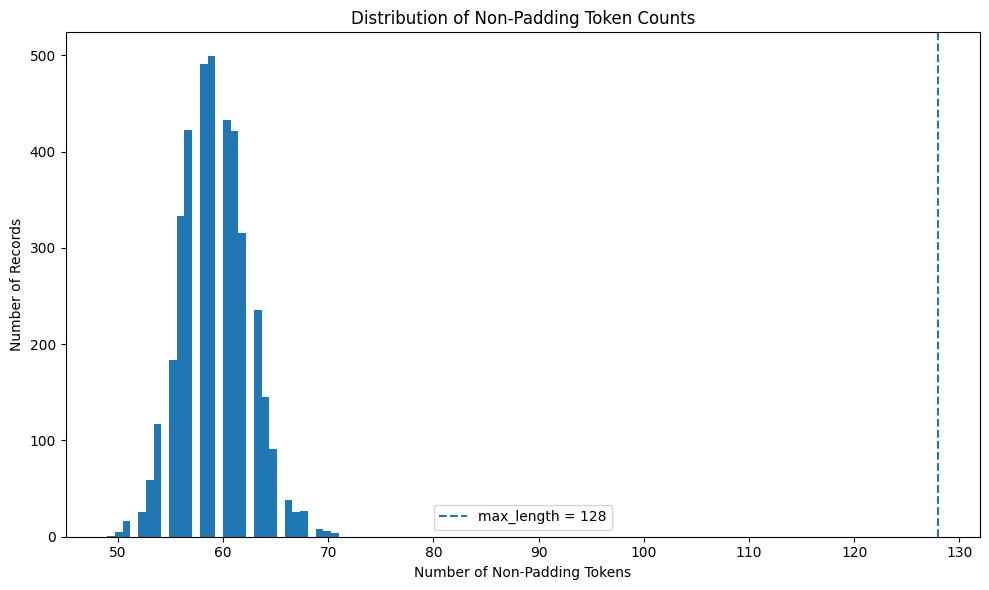

Truncation risk appears low: only 0.00% of records reach max_length=128.
Records requiring truncation: 0
Truncation percentage: 0.00%


In [8]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import numpy as np

# Calculate non-padding token count for every record
token_counts = []

for input_ids in tokenized_dataset["input_ids"]:
    count = sum(
        token_id != tokenizer.pad_token_id
        for token_id in input_ids
    )
    token_counts.append(count)

token_counts = np.array(token_counts)

# Basic statistics
print("Token count statistics")
print("----------------------")
print("Minimum tokens:", token_counts.min())
print("Maximum tokens:", token_counts.max())
print("Mean tokens:", round(token_counts.mean(), 2))
print("Median tokens:", np.median(token_counts))

# Count sequences reaching max_length
at_max_length = np.sum(token_counts >= MAX_LENGTH)

percentage_at_max = (
    at_max_length / len(token_counts)
) * 100

print("\nSequences reaching max_length:", at_max_length)
print(f"Percentage at max_length: {percentage_at_max:.2f}%")

plt.figure(figsize=(10, 6))

plt.hist(
    token_counts,
    bins=30
)

plt.axvline(
    MAX_LENGTH,
    linestyle="--",
    label=f"max_length = {MAX_LENGTH}"
)

plt.title("Distribution of Non-Padding Token Counts")
plt.xlabel("Number of Non-Padding Tokens")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()
if percentage_at_max > 5:
    print(
        f"WARNING: {percentage_at_max:.2f}% of records reach "
        f"max_length={MAX_LENGTH}."
    )
    print("Consider increasing max_length to 256.")
else:
    print(
        f"Truncation risk appears low: only "
        f"{percentage_at_max:.2f}% of records reach "
        f"max_length={MAX_LENGTH}."
    )
# Calculate original token lengths before truncation/padding

original_lengths = []

for text in df_clean["text"]:
    tokens = tokenizer(
        text,
        truncation=False,
        padding=False
    )["input_ids"]

    original_lengths.append(len(tokens))

original_lengths = np.array(original_lengths)

truncated_records = np.sum(original_lengths > MAX_LENGTH)
truncation_percentage = (
    truncated_records / len(original_lengths)
) * 100

print("Records requiring truncation:", truncated_records)
print(f"Truncation percentage: {truncation_percentage:.2f}%")

#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [14]:
# YOUR CODE HERE
import glob
from langchain_community.document_loaders import TextLoader
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="langchain_community")

# Find all Markdown SOP files
md_files = glob.glob(
    "corporate_policies/**/*.md",
    recursive=True
)

print("Number of SOP files found:", len(md_files))

documents = []

for file_path in md_files:
    loader = TextLoader(
        file_path,
        encoding="utf-8"
    )

    docs = loader.load()
    documents.extend(docs)

print("Number of LangChain Documents:", len(documents))

for i, doc in enumerate(documents):
    print(f"\n--- Document {i + 1} ---")
    print("Metadata:", doc.metadata)
    print("Content preview:")
    print(doc.page_content[:500])
#print("Page content type:", type(documents[0].page_content))
#print("Metadata type:", type(documents[0].metadata))
empty_documents = [
    i for i, doc in enumerate(documents)
    if not doc.page_content.strip()
]

print("Empty documents:", len(empty_documents))

print("\nExample metadata:")
for doc in documents[:3]:
    print(doc.metadata)

for doc in documents:
    source = doc.metadata.get("source")
    if source:
        doc.metadata["filename"] = Path(source).name

print("Example metadata after adding filename:")
print(documents[0].metadata)

Number of SOP files found: 13
Number of LangChain Documents: 13

--- Document 1 ---
Metadata: {'source': 'corporate_policies/billing_disputes.md'}
Content preview:
# Billing Disputes

## Scope
Use this when a customer questions a charge: an amount they do not recognize,
a charge larger than expected, a duplicate charge, or a charge after they
believed a service had ended. Refund eligibility itself is governed by the
refund policy; this procedure focuses on investigating the charge.

## Triage
1. Identify the exact charge: date, amount, and descriptor.
2. Match it to an order, subscription renewal, tax/shipping component, or
   pre-authorization hold.
3. Di

--- Document 2 ---
Metadata: {'source': 'corporate_policies/shipping_delays.md'}
Content preview:
# Shipping Delays

## Scope
This procedure covers orders that have shipped but are running behind the
estimated delivery date, as well as orders stuck in a pre-shipment state.

## Standard Timelines
Domestic orders deliver within 3–7 bu

### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [15]:
# YOUR CODE HERE
from sklearn.model_selection import train_test_split

# Reset index so indices can be used consistently
df_clean = df_clean.reset_index(drop=True)

# First split: 80% Train, 20% Temporary
train_indices, temp_indices = train_test_split(
    df_clean.index,
    test_size=0.20,
    random_state=42,
    stratify=df_clean["intent"]
)

# Second split: divide temporary 20% into 10% Validation and 10% Test
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=df_clean.loc[temp_indices, "intent"]
)

print("Total records:", len(df_clean))
print("Training records:", len(train_indices))
print("Validation records:", len(val_indices))
print("Test records:", len(test_indices))

df_train = df_clean.loc[train_indices].copy()
df_val = df_clean.loc[val_indices].copy()
df_test = df_clean.loc[test_indices].copy()

print("\nSplit sizes:")
print("Train:", len(df_train))
print("Validation:", len(df_val))
print("Test:", len(df_test))

print("Number of unique intents:")
print("Train:", df_train["intent"].nunique())
print("Validation:", df_val["intent"].nunique())
print("Test:", df_test["intent"].nunique())

print("\nIntent distribution (%):")

print("\nTrain:")
print(
    (df_train["intent"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nValidation:")
print(
    (df_val["intent"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTest:")
print(
    (df_test["intent"].value_counts(normalize=True) * 100)
    .round(2)
)

train_set = set(
    df_train["instruction"]
    .str.lower()
    .str.strip()
)

val_set = set(
    df_val["instruction"]
    .str.lower()
    .str.strip()
)

test_set = set(
    df_test["instruction"]
    .str.lower()
    .str.strip()
)

# Check every pair of splits
train_val_overlap = train_set & val_set
train_test_overlap = train_set & test_set
val_test_overlap = val_set & test_set

print("Train–Validation overlap:", len(train_val_overlap))
print("Train–Test overlap:", len(train_test_overlap))
print("Validation–Test overlap:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\n✓ Zero data leakage confirmed across all three splits.")

train_dataset = tokenized_dataset.select(train_indices.tolist())
val_dataset = tokenized_dataset.select(val_indices.tolist())
test_dataset = tokenized_dataset.select(test_indices.tolist())

print("Tokenized dataset splits:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

evaluation_columns = [
    "instruction",
    "intent",
    "category",
    "text"
]

df_test = df_test[evaluation_columns].copy()

print("\nTest DataFrame columns:")
print(df_test.columns.tolist())

print("\nTest DataFrame sample:")
print(df_test.head())

df_train = df_train[evaluation_columns].copy()
df_val = df_val[evaluation_columns].copy()

Total records: 3902
Training records: 3121
Validation records: 390
Test records: 391

Split sizes:
Train: 3121
Validation: 390
Test: 391
Number of unique intents:
Train: 27
Validation: 27
Test: 27

Intent distribution (%):

Train:
intent
review                      4.26
get_invoice                 4.23
create_account              4.17
set_up_shipping_address     4.07
contact_customer_service    4.04
payment_issue               4.04
check_payment_methods       4.04
contact_human_agent         3.97
complaint                   3.91
change_shipping_address     3.91
registration_problems       3.91
delivery_options            3.88
check_refund_policy         3.78
check_invoice               3.75
place_order                 3.68
track_refund                3.68
recover_password            3.65
check_cancellation_fee      3.65
delivery_period             3.56
track_order                 3.46
get_refund                  3.46
edit_account                3.43
delete_account              3.33
cha

---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [16]:
# YOUR CODE HERE
# Save cleaned and split datasets

df_clean.to_csv("cleaned_data.csv", index=False)
df_train.to_csv("train_data.csv", index=False)
df_val.to_csv("validation_data.csv", index=False)
df_test.to_csv("test_data.csv", index=False)

print("Readable datasets saved successfully:")
print(" - cleaned_data.csv")
print(" - train_data.csv")
print(" - validation_data.csv")
print(" - test_data.csv")

Readable datasets saved successfully:
 - cleaned_data.csv
 - train_data.csv
 - validation_data.csv
 - test_data.csv


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**